
# 📊 EDA de un portafolio de activos con Python
### Matplotlib · Seaborn · Pandas · yfinance

**Curso:** Lenguajes de programación  
**Tema:** Visualización y Análisis Exploratorio de Datos (EDA)  
**Caso:** análisis exploratorio de un portafolio de activos financieros

---

## 🎯 ¿Qué vamos a aprender?

Al terminar este notebook podrás:

- reconocer qué es una librería y para qué sirve;
- diferenciar **dato, variable, gráfico e interpretación**;
- crear gráficos básicos con **Matplotlib**;
- utilizar **Seaborn** para explorar distribuciones y relaciones;
- interpretar correctamente los gráficos;
- descargar datos históricos con **yfinance**;
- calcular rendimientos;
- explorar volatilidad, distribución y correlación;
- construir una primera lectura exploratoria de un portafolio.

> **Idea central:** un gráfico no es el resultado del análisis.  
> El gráfico es una herramienta que nos ayuda a **formular preguntas, encontrar patrones y comunicar hallazgos**.



## 🧭 Ruta de la clase

Trabajaremos de manera incremental:

**1. Datos → 2. Variables → 3. Gráfico → 4. Interpretación → 5. EDA → 6. Datos financieros reales**

| Etapa | Pregunta |
|---|---|
| Conceptos | ¿Qué estamos visualizando? |
| Matplotlib | ¿Cómo se construye un gráfico? |
| Seaborn | ¿Cómo exploramos una variable o relación? |
| EDA | ¿Qué patrones encontramos? |
| yfinance | ¿Cómo trabajamos con datos reales? |
| Portafolio | ¿Cómo se comportan conjuntamente los activos? |



# 1. Antes de graficar: pensemos como analistas

Supongamos que tenemos:

| Día | Precio |
|---:|---:|
| 1 | 100 |
| 2 | 103 |
| 3 | 101 |
| 4 | 108 |
| 5 | 112 |

Tenemos dos conceptos diferentes:

### Variable
Una característica que podemos observar o medir.  
Ejemplo: `Precio`.

### Observación
Un valor concreto de una variable.  
Ejemplo: el precio del día 4 es `108`.

### ¿Por qué graficar?

La tabla nos da los valores. El gráfico nos permite **ver la estructura de los datos**.

Por ejemplo:

- ¿el precio está aumentando?
- ¿hay caídas?
- ¿hay cambios bruscos?
- ¿existe una tendencia?

Ese proceso de preguntar, observar y encontrar patrones forma parte del **Análisis Exploratorio de Datos (EDA)**.



# 2. Las librerías que vamos a utilizar

Una **librería** es un conjunto de código reutilizable que otras personas han desarrollado para resolver problemas.

Hoy utilizaremos:

### 🐼 Pandas
Para trabajar con datos tabulares.

### 📈 Matplotlib
Para construir y personalizar visualizaciones.

### 🎨 Seaborn
Para crear visualizaciones estadísticas de forma sencilla y trabajar cómodamente con DataFrames.

### 💰 yfinance
Para obtener datos históricos de activos financieros desde Yahoo Finance.

La relación será:

```text
yfinance
   ↓
datos financieros
   ↓
Pandas
   ↓
transformaciones
   ↓
Matplotlib / Seaborn
   ↓
visualización
   ↓
interpretación
```


In [1]:
# Importamos las librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual básica
sns.set_theme(style="whitegrid")

# Para que los gráficos aparezcan dentro del notebook
%matplotlib inline



## ¿Qué significa `import`?

Cuando escribimos:

```python
import matplotlib.pyplot as plt
```

estamos diciendo:

> "Quiero utilizar el módulo `pyplot` de la librería `matplotlib` y voy a llamarlo `plt`."

Por eso posteriormente podemos escribir:

```python
plt.plot(...)
```

El nombre `plt` es un **alias**. No es obligatorio llamarlo así, pero es una convención muy utilizada.

Lo mismo ocurre con:

```python
import seaborn as sns
import pandas as pd
import numpy as np
```



# 3. Nuestro primer gráfico: de una tabla a una visualización

Comencemos con datos muy pequeños para entender **qué hace cada instrucción**.

Tenemos el precio de un activo durante cinco días.


In [2]:
dias = [1, 2, 3, 4, 5]
precios = [100, 103, 101, 108, 112]

datos_ejemplo = pd.DataFrame({
    "Día": dias,
    "Precio": precios
})

datos_ejemplo


,Día,Precio
0,1,100
1,2,103
2,3,101
3,4,108
4,5,112



### Primer intento

Queremos representar:

- eje X → día
- eje Y → precio

La función `plot()` recibe normalmente una serie de valores para X y otra para Y.


In [ ]:
plt.plot(dias, precios)
plt.show()



## 🔎 ¿Qué acaba de ocurrir?

`plt.plot(x, y)`:

- toma los valores de `x`;
- toma los valores de `y`;
- coloca cada par `(x, y)` en el plano;
- conecta los puntos.

En nuestro ejemplo:

```text
(1,100)
(2,103)
(3,101)
(4,108)
(5,112)
```

### ¿Cómo lo interpretamos?

No debemos decir simplemente "el gráfico sube".

Podemos decir:

> **El precio presenta una tendencia general creciente durante el período observado, aunque existe una disminución entre los días 2 y 3.**

Esa segunda frase ya es una **interpretación**.



# 4. Hacer que el gráfico comunique mejor

Un gráfico debe permitir que otra persona entienda rápidamente:

1. **qué está viendo**;
2. **qué representan los ejes**;
3. **qué unidad se está utilizando**;
4. **qué período se está observando**.

Para eso agregamos título y etiquetas.


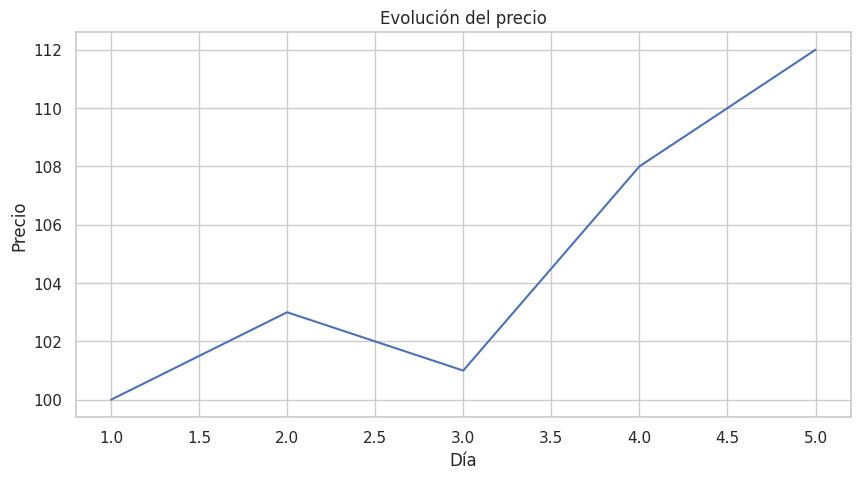

In [3]:
plt.figure(figsize=(10, 5))

plt.plot(dias, precios)

plt.title("Evolución del precio")
plt.xlabel("Día")
plt.ylabel("Precio")

plt.show()



## 🧩 Anatomía de un gráfico

```text
                 TÍTULO
        Evolución del precio

  Y
  ↑
  │             ●
  │          ●
  │     ●
  │        ●
  │  ●
  └──────────────────────→ X
       Día
```

### Elementos principales

- **Título:** comunica qué estamos observando.
- **Eje X:** normalmente representa tiempo o una variable explicativa.
- **Eje Y:** representa la variable que queremos analizar.
- **Línea/puntos:** representan los datos.
- **Leyenda:** identifica las series cuando tenemos varias.



# 5. La interfaz orientada a objetos de Matplotlib

Hasta ahora utilizamos `plt` directamente.

Existe otra forma muy importante:

```python
fig, ax = plt.subplots()
```

Aquí aparecen dos objetos:

### `fig`
Es la **figura completa**, el espacio donde estará nuestro gráfico.

### `ax`
Es el **área de ejes** donde realmente dibujamos.

Una forma sencilla de imaginarlo:

```text
Figure
┌─────────────────────────────┐
│                             │
│       Axes                  │
│     ┌───────────────┐       │
│     │   gráfico     │       │
│     │               │       │
│     └───────────────┘       │
│                             │
└─────────────────────────────┘
```


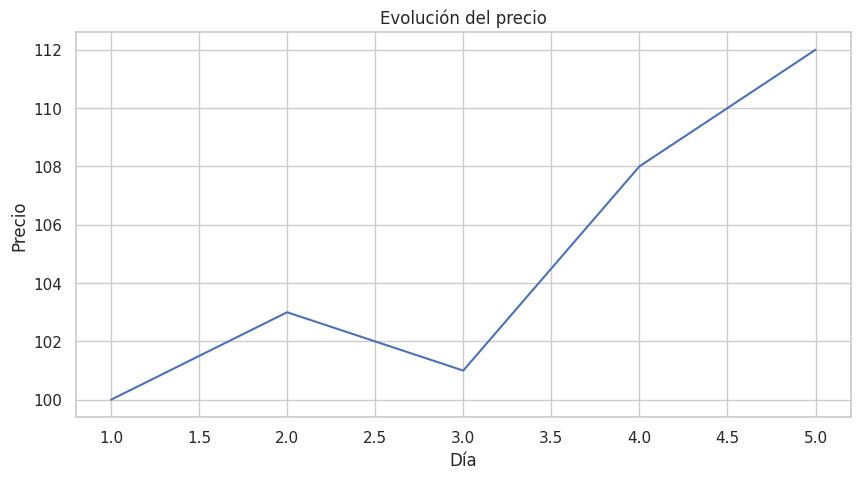

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(dias, precios)

ax.set_title("Evolución del precio")
ax.set_xlabel("Día")
ax.set_ylabel("Precio")

plt.show()



### ¿Por qué aprender esta forma?

Cuando los gráficos se vuelven más complejos, trabajar con `fig` y `ax` nos da mayor control.

Por ejemplo, podemos tener varios gráficos dentro de una misma figura y controlar cada eje por separado.

**Regla práctica para la clase:**

- `plt.plot()` → muy útil para comenzar.
- `fig, ax = plt.subplots()` → recomendable cuando queremos construir gráficos de forma más estructurada.



# 6. Gráficos de varias series

Ahora supongamos que tenemos tres activos.


In [5]:
precios_portafolio = pd.DataFrame({
    "AAPL": [100, 103, 101, 108, 112],
    "MSFT": [100, 102, 104, 106, 109],
    "NVDA": [100, 98, 105, 110, 120]
}, index=[1, 2, 3, 4, 5])

precios_portafolio


,AAPL,MSFT,NVDA
1,100,100,100
2,103,102,98
3,101,104,105
4,108,106,110
5,112,109,120



Si graficamos los precios directamente, podemos comparar las series.

Pero aparece un problema importante:

> ¿Cómo comparamos activos que originalmente tienen precios diferentes?

Por ahora nuestros datos comienzan todos en 100. Esto es intencional: queremos concentrarnos en la **forma de la serie** antes de introducir los rendimientos.


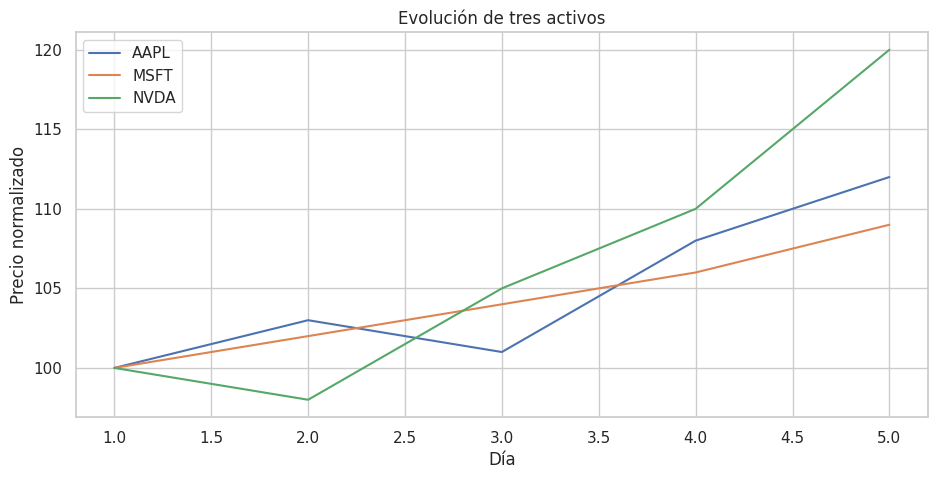

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(precios_portafolio.index, precios_portafolio["AAPL"], label="AAPL")
ax.plot(precios_portafolio.index, precios_portafolio["MSFT"], label="MSFT")
ax.plot(precios_portafolio.index, precios_portafolio["NVDA"], label="NVDA")

ax.set_title("Evolución de tres activos")
ax.set_xlabel("Día")
ax.set_ylabel("Precio normalizado")
ax.legend()

plt.show()



## 🧠 Interpretación

Observe primero, **después interprete**.

Preguntas:

1. ¿Cuál serie termina más arriba?
2. ¿Cuál presenta más cambios?
3. ¿Hay momentos en los que dos activos se mueven en direcciones diferentes?
4. ¿Podemos concluir cuál es "mejor" solamente con este gráfico?

La última pregunta es importante:

> **No.** Un gráfico puede mostrar comportamiento histórico, pero no convierte automáticamente ese comportamiento en una recomendación de inversión.



# 7. Seaborn: visualización orientada al análisis estadístico

Seaborn está construido sobre Matplotlib y facilita muchos gráficos estadísticos.

Una ventaja importante es que puede trabajar directamente con estructuras de Pandas.

Vamos a utilizar primero un **histograma**.


In [7]:
# Generamos una muestra sencilla de rendimientos

np.random.seed(42)

rendimientos_ejemplo = np.random.normal(
    loc=0.001,
    scale=0.02,
    size=500
)

rendimientos_ejemplo[:10]


array([ 0.01093428, -0.00176529,  0.01395377,  0.0314606 , -0.00368307,
       -0.00368274,  0.03258426,  0.01634869, -0.00838949,  0.0118512 ])


## ¿Qué pregunta responde un histograma?

Un histograma permite observar cómo se distribuyen los valores.

Por ejemplo:

> ¿En qué rango se concentran los rendimientos?


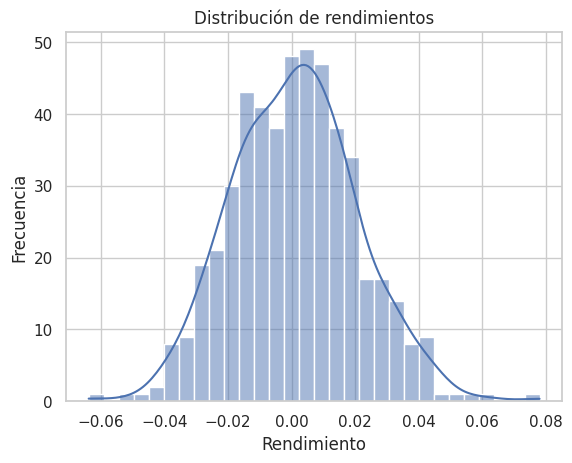

In [8]:
sns.histplot(
    rendimientos_ejemplo,
    bins=30,
    kde=True
)

plt.title("Distribución de rendimientos")
plt.xlabel("Rendimiento")
plt.ylabel("Frecuencia")

plt.show()



## 🔎 ¿Cómo interpretar un histograma?

Observemos:

### Centro
¿Dónde se concentran la mayoría de los valores?

### Dispersión
¿Qué tan extendidos están los datos?

### Colas
¿Hay valores alejados del centro?

### Forma
¿La distribución parece simétrica o presenta algún sesgo?

**Importante:** la forma del histograma depende de decisiones como el número de `bins`. No debemos interpretar cada detalle visual como una propiedad exacta de los datos.



# 8. Boxplot: detectar dispersión y valores extremos

Un boxplot resume visualmente una distribución.

Conceptualmente muestra:

- mediana;
- cuartiles;
- rango intercuartílico;
- posibles valores extremos.



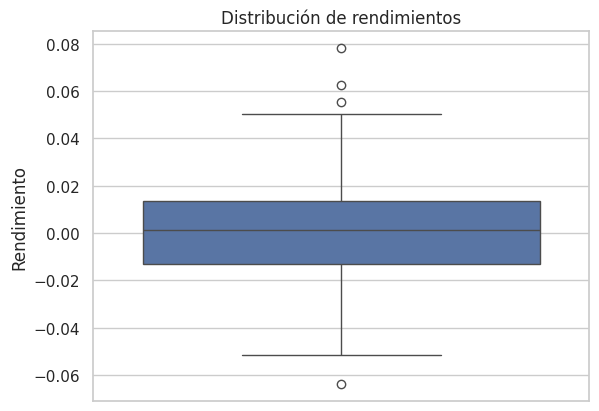

In [9]:
sns.boxplot(y=rendimientos_ejemplo)

plt.title("Distribución de rendimientos")
plt.ylabel("Rendimiento")

plt.show()



### Preguntas para interpretar

- ¿Dónde está la mediana?
- ¿Qué tan grande es la caja?
- ¿Qué tan largos son los bigotes?
- ¿Aparecen observaciones alejadas?

El objetivo no es memorizar la forma del dibujo.

El objetivo es poder decir:

> "La distribución presenta mayor/menor dispersión..."

y justificarlo a partir del gráfico.



# 9. Scatter plot: estudiar relaciones

Ahora queremos estudiar dos variables.

Por ejemplo:

> ¿Los cambios diarios de AAPL y MSFT tienden a ocurrir en la misma dirección?

Para eso usamos un **scatter plot**.

Cada punto representa una observación.


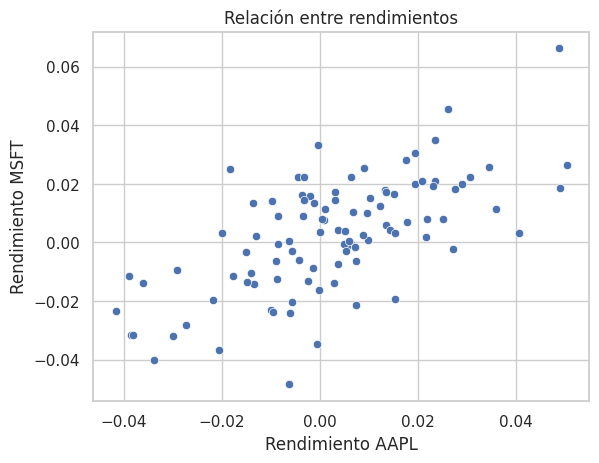

In [10]:
np.random.seed(10)

aapl = np.random.normal(0.001, 0.02, 100)
msft = aapl * 0.6 + np.random.normal(0, 0.015, 100)

sns.scatterplot(x=aapl, y=msft)

plt.title("Relación entre rendimientos")
plt.xlabel("Rendimiento AAPL")
plt.ylabel("Rendimiento MSFT")

plt.show()



## Interpretación

Buscamos patrones:

- nube ascendente → posible relación positiva;
- nube descendente → posible relación negativa;
- nube sin orientación clara → relación lineal débil o inexistente.

Pero recuerda:

> **Correlación no significa causalidad.**

Dos variables pueden moverse juntas sin que una sea la causa de la otra.



# 10. Correlación y mapa de calor

La correlación permite cuantificar la relación lineal entre dos variables.

En Python:

```python
df.corr()
```

produce una matriz de correlaciones.

Valores cercanos a:

- `1` → relación lineal positiva fuerte;
- `0` → relación lineal débil;
- `-1` → relación lineal negativa fuerte.

Veámoslo visualmente.


In [11]:
datos_rendimientos = pd.DataFrame({
    "AAPL": aapl,
    "MSFT": msft,
    "NVDA": aapl * 0.3 + np.random.normal(0, 0.025, 100)
})

correlacion = datos_rendimientos.corr()

correlacion


,AAPL,MSFT,NVDA
AAPL,1.000000,0.648544,0.207646
MSFT,0.648544,1.000000,0.205384
NVDA,0.207646,0.205384,1.000000


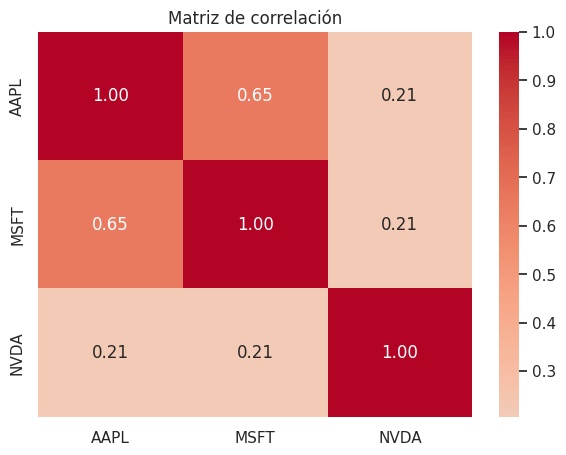

In [12]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlación")

plt.show()



## 🧠 Interpretar el heatmap

La matriz permite responder rápidamente:

> ¿Qué activos tienen comportamientos más similares?

Pero debemos tener cuidado:

- la correlación mide principalmente **relación lineal**;
- una correlación histórica no garantiza que se mantenga igual;
- correlación no significa causalidad;
- el período elegido afecta el resultado.

Para un análisis financiero serio también debemos considerar el período, frecuencia, calidad de datos y contexto del mercado.



# 11. Ahora sí: datos reales con yfinance 💰

Hasta este momento utilizamos datos pequeños o simulados para entender la visualización.

Ahora vamos a trabajar con datos reales.

Instalación, si el entorno todavía no tiene la librería:

```bash
pip install yfinance
```

Importamos:


In [ ]:
import yfinance as yf



## ¿Qué activos vamos a estudiar?

Usaremos como ejemplo:

- `AAPL` — Apple
- `MSFT` — Microsoft
- `GOOGL` — Alphabet
- `AMZN` — Amazon
- `NVDA` — NVIDIA

Los símbolos son **tickers**, identificadores utilizados para localizar activos en los mercados.

> Los datos obtenidos mediante servicios externos pueden cambiar con el tiempo. Para una clase de EDA esto es útil: cada estudiante puede obtener una fotografía diferente del período consultado.


In [14]:
import yfinance as yf

activos = ["AAPL", "MSFT", "GOOGL", "AMZN", "NVDA"]

precios = yf.download(
    activos,
    start="2024-01-01",
    end="2026-01-01",
    auto_adjust=True
)

precios.head()


[*********************100%***********************]  5 of 5 completed


Price            Close                                                 \
Ticker            AAPL        AMZN       GOOGL        MSFT       NVDA   
Date                                                                    
2024-01-02  183.404007  149.929993  136.867599  363.117889  48.028797   
2024-01-03  182.030762  148.470001  137.610535  362.853577  47.431522   
2024-01-04  179.718933  144.570007  135.104401  360.249115  47.859283   
2024-01-05  178.997742  145.240005  134.450607  360.063141  48.955109   
2024-01-08  183.324966  149.100006  137.531281  366.858063  52.101986   

Price             High                                                 ...  \
Ticker            AAPL        AMZN       GOOGL        MSFT       NVDA  ...   
Date                                                                   ...   
2024-01-02  186.170285  152.380005  138.135533  368.042749  49.152539  ...   
2024-01-03  183.641134  151.050003  138.313849  365.457980  48.044743  ...   
2024-01-04  180.884713  147.380005  137.848295  365.301261  48.359832  ...   
2024-01-05  180.558713  146.589996  135.867136  364.283049  49.403809  ...   
2024-01-08  183.364493  149.399994  137.699676  367.357412  52.123926  ...   

Price             Open                                                 \
Ticker            AAPL        AMZN       GOOGL        MSFT       NVDA   
Date                                                                    
2024-01-02  184.895814  151.539993  137.244022  366.045381  49.101688   
2024-01-03  182.001124  149.199997  135.956278  361.296815  47.347766   
2024-01-04  179.956033  145.589996  137.115265  362.922062  47.628948   
2024-01-05  179.797998  144.690002  135.460997  361.257641  48.321945   
2024-01-08  179.896761  146.740005  135.005314  361.580713  49.368910   

Price         Volume                                           
Ticker          AAPL      AMZN     GOOGL      MSFT       NVDA  
Date                                                           
2024-01-02  82488700  47339400  23711200  25258600  411254000  
2024-01-03  58414500  49425500  24212100  23083500  320896000  
2024-01-04  71983600  56039800  27137700  20901500  306535000  
2024-01-05  62379700  45153100  22513900  21004600  415039000  
2024-01-08  59144500  46757100  21404000  23134000  642510000  

[5 rows x 25 columns]


# 12. Antes de graficar: conozcamos nuestros datos

Una regla fundamental de EDA:

> **No empieces a graficar sin conocer primero el DataFrame.**

Preguntas básicas:

- ¿cuántas filas tenemos?
- ¿cuántas columnas?
- ¿qué tipo de datos?
- ¿hay valores faltantes?
- ¿qué período cubren?


In [15]:
print("Dimensiones:", precios.shape)

precios.info()


Dimensiones: (502, 25)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 502 entries, 2024-01-02 to 2025-12-31
Data columns (total 25 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   (Close, AAPL)    502 non-null    float64
 1   (Close, AMZN)    502 non-null    float64
 2   (Close, GOOGL)   502 non-null    float64
 3   (Close, MSFT)    502 non-null    float64
 4   (Close, NVDA)    502 non-null    float64
 5   (High, AAPL)     502 non-null    float64
 6   (High, AMZN)     502 non-null    float64
 7   (High, GOOGL)    502 non-null    float64
 8   (High, MSFT)     502 non-null    float64
 9   (High, NVDA)     502 non-null    float64
 10  (Low, AAPL)      502 non-null    float64
 11  (Low, AMZN)      502 non-null    float64
 12  (Low, GOOGL)     502 non-null    float64
 13  (Low, MSFT)      502 non-null    float64
 14  (Low, NVDA)      502 non-null    float64
 15  (Open, AAPL)     502 non-null    float64
 16  (Open, AMZN)     502

In [16]:
precios.describe()


Price        Close                                                  \
Ticker        AAPL        AMZN       GOOGL        MSFT        NVDA   
count   502.000000  502.000000  502.000000  502.000000  502.000000   
mean    218.163910  201.084920  186.196406  436.391724  130.434591   
std      29.061802   23.894482   44.695115   44.590889   36.478682   
min     163.220627  144.570007  130.161407  350.446075   47.431522   
25%     197.301437  182.045002  160.382679  404.577202  107.877951   
50%     220.355469  199.269997  171.818100  420.492264  129.622070   
75%     234.987217  223.067505  193.867241  475.532753  157.790546   
max     285.413116  254.000000  322.601013  537.646423  206.545166   

Price         High                                                  ...  \
Ticker        AAPL        AMZN       GOOGL        MSFT        NVDA  ...   
count   502.000000  502.000000  502.000000  502.000000  502.000000  ...   
mean    220.247260  203.257610  188.240374  439.904431  132.605680  ...   
std      29.157374   24.065589   45.248697   44.664830   36.763190  ...   
min     164.605523  146.589996  131.984083  360.250949   48.044743  ...   
25%     199.331456  184.752499  162.219157  407.837397  110.606054  ...   
50%     222.591318  200.525002  173.761181  423.625047  132.120719  ...   
75%     237.294625  225.872498  195.231444  480.116581  158.770632  ...   
max     287.836529  258.600006  327.977016  550.013050  211.682867  ...   

Price         Open                                                  \
Ticker        AAPL        AMZN       GOOGL        MSFT        NVDA   
count   502.000000  502.000000  502.000000  502.000000  502.000000   
mean    217.941192  201.160956  186.098552  436.394022  130.481371   
std      29.027178   24.115082   44.736022   44.931146   36.636462   
min     163.566856  144.690002  130.636902  346.808831   47.347766   
25%     196.633056  182.320004  160.184675  404.190604  107.114859   
50%     219.779636  199.305000  172.185854  420.292298  129.651078   
75%     234.190526  223.520004  192.999171  476.422511  157.940170   
max     285.423116  255.360001  325.363817  549.795172  207.582657   

Price         Volume                                                          
Ticker          AAPL          AMZN         GOOGL          MSFT          NVDA  
count   5.020000e+02  5.020000e+02  5.020000e+02  5.020000e+02  5.020000e+02  
mean    5.564712e+07  4.270025e+07  3.183945e+07  2.138683e+07  2.992817e+08  
std     2.732569e+07  1.823593e+07  1.448971e+07  8.027734e+06  1.537611e+08  
min     1.791060e+07  1.142050e+07  1.009740e+07  5.855900e+06  6.552850e+07  
25%     4.132715e+07  3.153310e+07  2.236578e+07  1.632950e+07  1.841153e+08  
50%     4.890840e+07  3.871275e+07  2.853320e+07  1.958820e+07  2.505988e+08  
75%     6.041002e+07  4.680382e+07  3.582398e+07  2.359505e+07  3.779842e+08  
max     3.186799e+08  1.663408e+08  1.274901e+08  7.083610e+07  1.142269e+09  

[8 rows x 25 columns]

In [17]:
precios.isna().sum()


Price   Ticker
Close   AAPL      0
        AMZN      0
        GOOGL     0
        MSFT      0
        NVDA      0
High    AAPL      0
        AMZN      0
        GOOGL     0
        MSFT      0
        NVDA      0
Low     AAPL      0
        AMZN      0
        GOOGL     0
        MSFT      0
        NVDA      0
Open    AAPL      0
        AMZN      0
        GOOGL     0
        MSFT      0
        NVDA      0
Volume  AAPL      0
        AMZN      0
        GOOGL     0
        MSFT      0
        NVDA      0
dtype: int64


### 🧪 Mini-reto

Antes de continuar, responde:

1. ¿Cuántas observaciones tenemos?
2. ¿Cuál es la primera fecha?
3. ¿Cuál es la última fecha?
4. ¿Existen valores faltantes?
5. ¿Qué representa cada nivel de columnas?

**No continúes hasta intentar responderlas.**


In [18]:
print("1. Dimensiones (Filas, Columnas):", precios.shape)
print("2. Primera fecha:", precios.index[0])
print("3. Última fecha:", precios.index[-1])
print("4. Valores faltantes totales:", precios.isnull().sum().sum())
print("5. Estructura de columnas:", precios.columns)

1. Dimensiones (Filas, Columnas): (502, 25)
2. Primera fecha: 2024-01-02 00:00:00
3. Última fecha: 2025-12-31 00:00:00
4. Valores faltantes totales: 0
5. Estructura de columnas: MultiIndex([( 'Close',  'AAPL'),
            ( 'Close',  'AMZN'),
            ( 'Close', 'GOOGL'),
            ( 'Close',  'MSFT'),
            ( 'Close',  'NVDA'),
            (  'High',  'AAPL'),
            (  'High',  'AMZN'),
            (  'High', 'GOOGL'),
            (  'High',  'MSFT'),
            (  'High',  'NVDA'),
            (   'Low',  'AAPL'),
            (   'Low',  'AMZN'),
            (   'Low', 'GOOGL'),
            (   'Low',  'MSFT'),
            (   'Low',  'NVDA'),
            (  'Open',  'AAPL'),
            (  'Open',  'AMZN'),
            (  'Open', 'GOOGL'),
            (  'Open',  'MSFT'),
            (  'Open',  'NVDA'),
            ('Volume',  'AAPL'),
            ('Volume',  'AMZN'),
            ('Volume', 'GOOGL'),
            ('Volume',  'MSFT'),
            ('Volume',  'NVDA'


# 13. Seleccionar el precio de cierre

`yfinance` devuelve varias variables para cada activo, entre ellas:

- Open
- High
- Low
- Close
- Volume

Para nuestro primer análisis utilizaremos **Close**, el precio de cierre ajustado según la configuración utilizada.



In [19]:
cierre = precios["Close"]

cierre.head()


Ticker,AAPL,AMZN,GOOGL,MSFT,NVDA
Date,,,,,
2024-01-02,183.404007,149.929993,136.867599,363.117889,48.028797
2024-01-03,182.030762,148.470001,137.610535,362.853577,47.431522
2024-01-04,179.718933,144.570007,135.104401,360.249115,47.859283
2024-01-05,178.997742,145.240005,134.450607,360.063141,48.955109
2024-01-08,183.324966,149.100006,137.531281,366.858063,52.101986



## Visualicemos los precios

Primera pregunta del EDA:

> **¿Cómo evolucionaron los precios de los activos durante el período?**


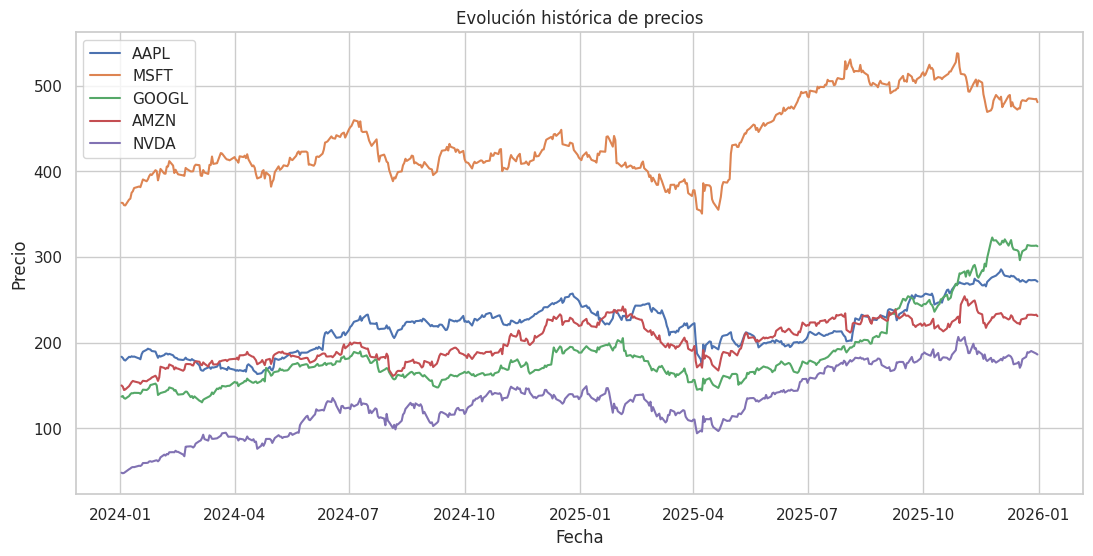

In [20]:
fig, ax = plt.subplots(figsize=(13, 6))

for activo in activos:
    ax.plot(cierre.index, cierre[activo], label=activo)

ax.set_title("Evolución histórica de precios")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio")
ax.legend()

plt.show()



## ⚠️ Una dificultad de comparar precios

AAPL puede tener un precio nominal diferente de NVDA, MSFT, etc.

Eso hace que comparar las alturas directamente pueda ser engañoso.

Una solución sencilla para estudiar **crecimiento relativo** es normalizar las series.

Por ejemplo:

```python
precio_normalizado = precio / precio_inicial * 100
```

Así todos comienzan en 100.


In [22]:
cierre_normalizado = cierre / cierre.iloc[0] * 100

cierre_normalizado.head()


Ticker,AAPL,AMZN,GOOGL,MSFT,NVDA
Date,,,,,
2024-01-02,100.000000,100.000000,100.000000,100.000000,100.000000
2024-01-03,99.251246,99.026218,100.542813,99.927210,98.756424
2024-01-04,97.990734,96.425008,98.711749,99.209961,99.647058
2024-01-05,97.597509,96.871882,98.234065,99.158745,101.928659
2024-01-08,99.956904,99.446417,100.484907,101.030016,108.480722


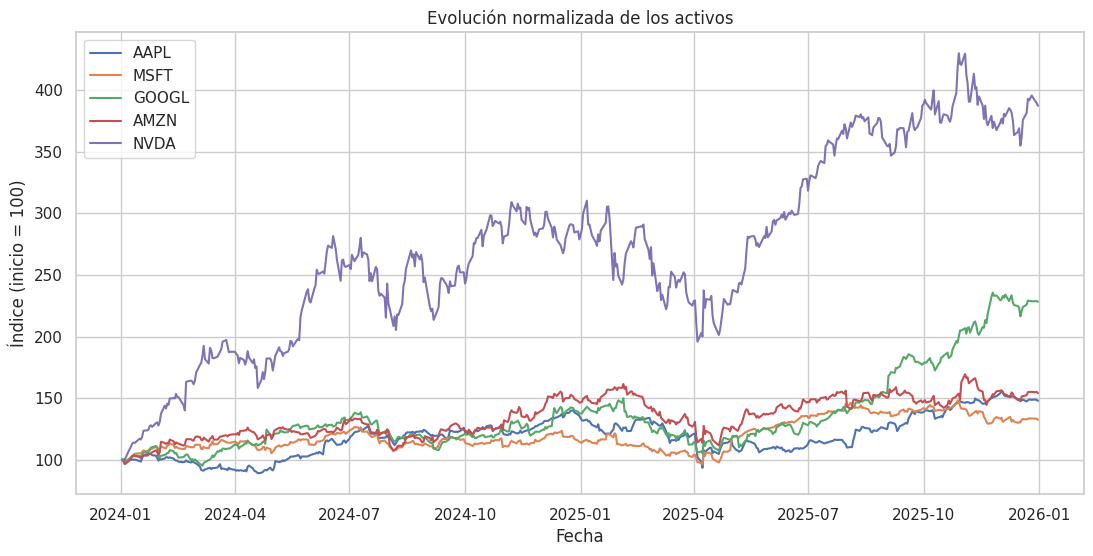

In [23]:
fig, ax = plt.subplots(figsize=(13, 6))

for activo in activos:
    ax.plot(
        cierre_normalizado.index,
        cierre_normalizado[activo],
        label=activo
    )

ax.set_title("Evolución normalizada de los activos")
ax.set_xlabel("Fecha")
ax.set_ylabel("Índice (inicio = 100)")
ax.legend()

plt.show()



### ¿Qué pregunta responde este gráfico?

No responde:

> "¿Cuál tiene el precio más alto?"

Responde mejor:

> **"¿Cómo cambió cada activo respecto a su propio punto inicial?"**

Esta distinción es fundamental en análisis de datos financieros.



# 14. Rendimientos: transformar los precios

En análisis financiero suele ser útil estudiar **rendimientos** en lugar de precios.

Un rendimiento porcentual simple entre dos períodos puede calcularse como:

\[
R_t = \frac{P_t-P_{t-1}}{P_{t-1}}
\]

En Pandas podemos obtenerlo con:

```python
pct_change()
```


In [24]:
rendimientos = cierre.pct_change()

rendimientos.head()


Ticker,AAPL,AMZN,GOOGL,MSFT,NVDA
Date,,,,,
2024-01-02,NaN,NaN,NaN,NaN,NaN
2024-01-03,-0.007488,-0.009738,0.005428,-0.000728,-0.012436
2024-01-04,-0.012700,-0.026268,-0.018212,-0.007178,0.009018
2024-01-05,-0.004013,0.004634,-0.004839,-0.000516,0.022897
2024-01-08,0.024175,0.026577,0.022913,0.018871,0.064281



El primer registro normalmente será `NaN` porque no tenemos un precio anterior con el cual compararlo.

Eliminemos esos valores para las visualizaciones que lo necesiten.


In [25]:
rendimientos = rendimientos.dropna()

rendimientos.head()


Ticker,AAPL,AMZN,GOOGL,MSFT,NVDA
Date,,,,,
2024-01-03,-0.007488,-0.009738,0.005428,-0.000728,-0.012436
2024-01-04,-0.012700,-0.026268,-0.018212,-0.007178,0.009018
2024-01-05,-0.004013,0.004634,-0.004839,-0.000516,0.022897
2024-01-08,0.024175,0.026577,0.022913,0.018871,0.064281
2024-01-09,-0.002263,0.015225,0.015197,0.002936,0.016975



# 15. EDA de los rendimientos

### Pregunta 1
**¿Cómo se comportan los rendimientos a través del tiempo?**


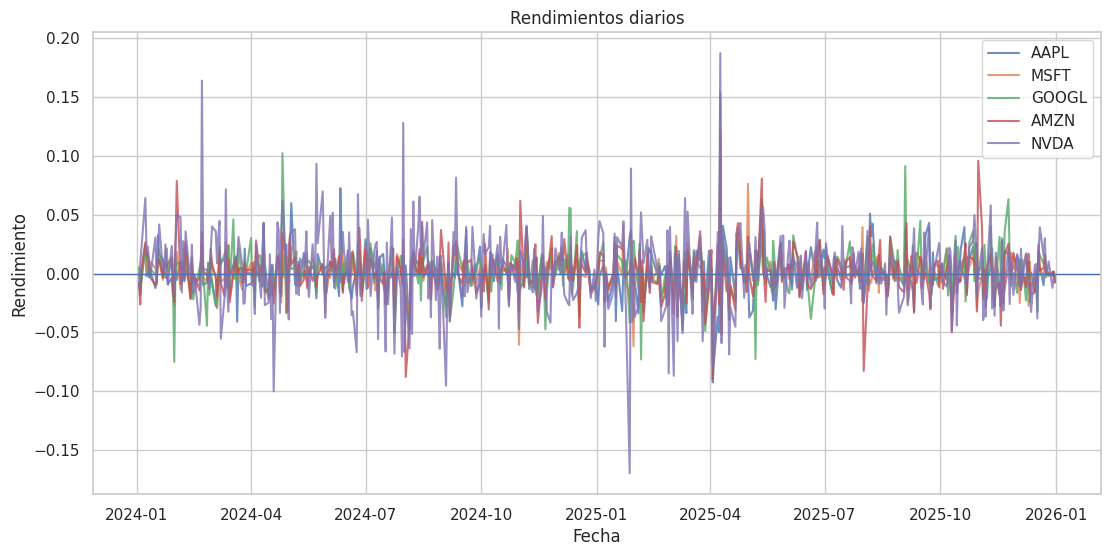

In [26]:
fig, ax = plt.subplots(figsize=(13, 6))

for activo in activos:
    ax.plot(
        rendimientos.index,
        rendimientos[activo],
        label=activo,
        alpha=0.8
    )

ax.axhline(0, linewidth=1)
ax.set_title("Rendimientos diarios")
ax.set_xlabel("Fecha")
ax.set_ylabel("Rendimiento")
ax.legend()

plt.show()



### Interpretación

La línea horizontal en cero nos ayuda a distinguir:

- valores positivos → rendimiento positivo;
- valores negativos → rendimiento negativo.

Busca:

- períodos de mayor variabilidad;
- movimientos extremos;
- momentos donde varios activos caen simultáneamente;
- diferencias entre activos.

**No confundas variabilidad con rendimiento.**

Un activo puede tener grandes movimientos hacia arriba y hacia abajo y terminar cerca del punto inicial.



# 16. Distribución de rendimientos

Ahora usamos Seaborn para estudiar una variable desde otro ángulo.

Pregunta:

> **¿Cómo se distribuyen los rendimientos diarios de cada activo?**


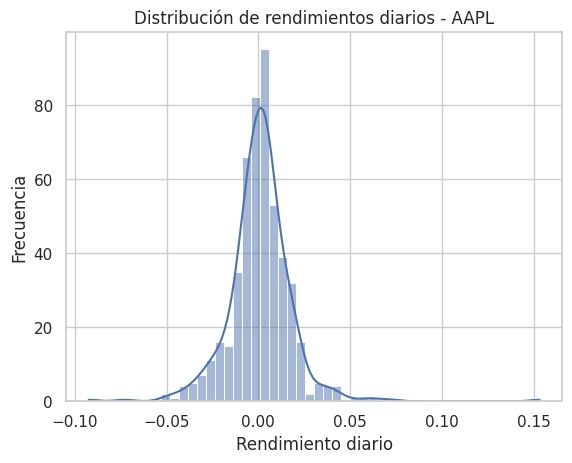

In [27]:
sns.histplot(
    data=rendimientos,
    x="AAPL",
    bins=50,
    kde=True
)

plt.title("Distribución de rendimientos diarios - AAPL")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")

plt.show()


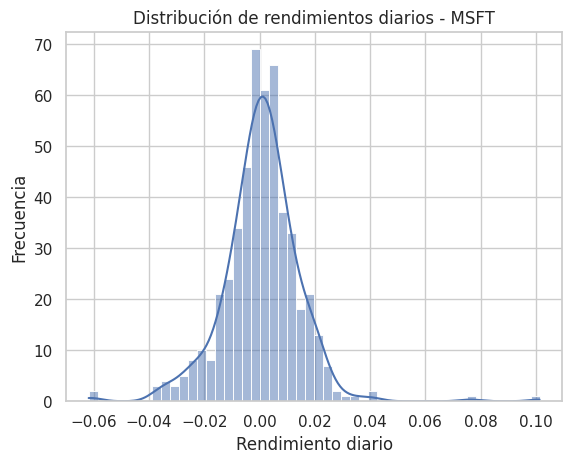

In [30]:
sns.histplot(
    data=rendimientos,
    x="MSFT",
    bins=50,
    kde=True
)

plt.title("Distribución de rendimientos diarios - MSFT")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")

plt.show()



## 🧪 Cambia el activo

Modifica `"AAPL"` por:

```python
"MSFT"
"GOOGL"
"AMZN"
"NVDA"
```

### Pregunta

¿Qué diferencias observas entre las distribuciones?

No busques solamente cuál "se ve mejor".

Describe:

- centro;
- dispersión;
- valores extremos;
- forma de la distribución.



# 17. Comparar la dispersión con un boxplot

Ahora podemos comparar todos los activos simultáneamente.


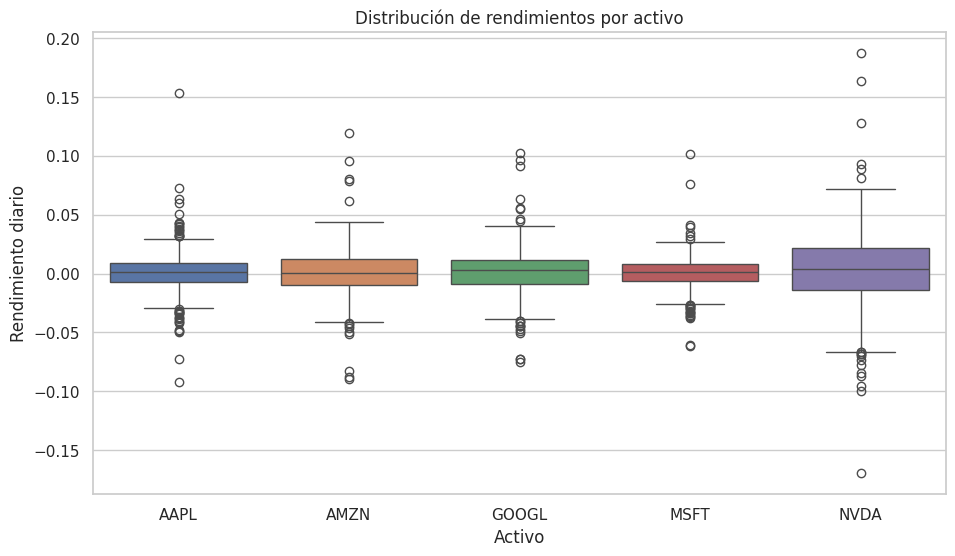

In [28]:
plt.figure(figsize=(11, 6))

sns.boxplot(data=rendimientos)

plt.title("Distribución de rendimientos por activo")
plt.xlabel("Activo")
plt.ylabel("Rendimiento diario")

plt.show()



### Preguntas de análisis

1. ¿Qué activos muestran mayor dispersión?
2. ¿Qué activos presentan más observaciones alejadas?
3. ¿Las medianas están cerca de cero?
4. ¿Qué información perderíamos si solo observáramos el precio?

Aquí aparece una idea importante:

> **Una buena visualización permite comparar una propiedad concreta de los datos.**



# 18. Matriz de correlación del portafolio

Ahora llegamos a una de las visualizaciones más importantes para nuestro caso.

Pregunta:

> **¿Cómo se relacionan los rendimientos de los activos entre sí?**


In [31]:
correlacion = rendimientos.corr()

correlacion


Ticker,AAPL,AMZN,GOOGL,MSFT,NVDA
Ticker,,,,,
AAPL,1.000000,0.484033,0.442986,0.479061,0.350518
AMZN,0.484033,1.000000,0.540440,0.625640,0.505377
GOOGL,0.442986,0.540440,1.000000,0.485902,0.398910
MSFT,0.479061,0.625640,0.485902,1.000000,0.549245
NVDA,0.350518,0.505377,0.398910,0.549245,1.000000


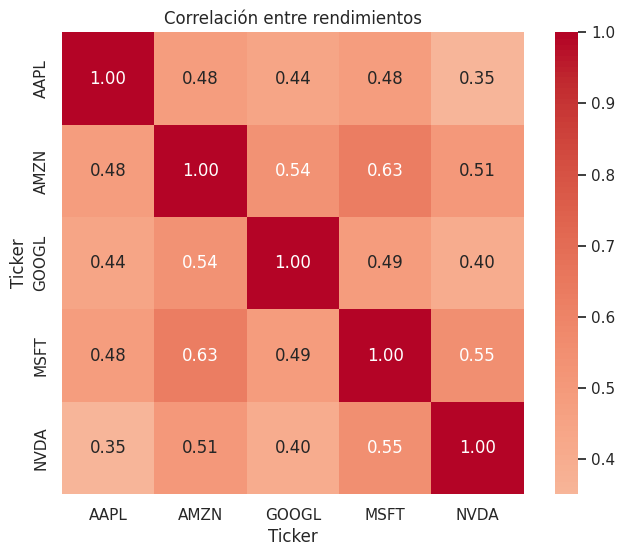

In [32]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlación entre rendimientos")

plt.show()



## 🧠 ¿Cómo leer la matriz?

Supongamos que encontramos:

```text
             AAPL    MSFT
AAPL          1.00   0.70
MSFT          0.70   1.00
```

La diagonal es 1 porque cada activo está perfectamente correlacionado consigo mismo.

Un valor de `0.70` indica una relación lineal positiva relativamente alta en el período analizado.

### Pregunta de portafolio

Si dos activos presentan una correlación elevada:

> ¿Qué implica esto para la diversificación?

Una posible interpretación es que **pueden proporcionar menos diversificación entre sí que dos activos con una correlación menor**, aunque la diversificación real depende de muchos otros factores.

No debemos convertir la correlación, por sí sola, en una recomendación de inversión.



# 19. Scatter plot: profundicemos en una pareja

Seleccionemos dos activos:

```python
AAPL
MSFT
```

Cada punto representa un día.

- X → rendimiento de AAPL
- Y → rendimiento de MSFT



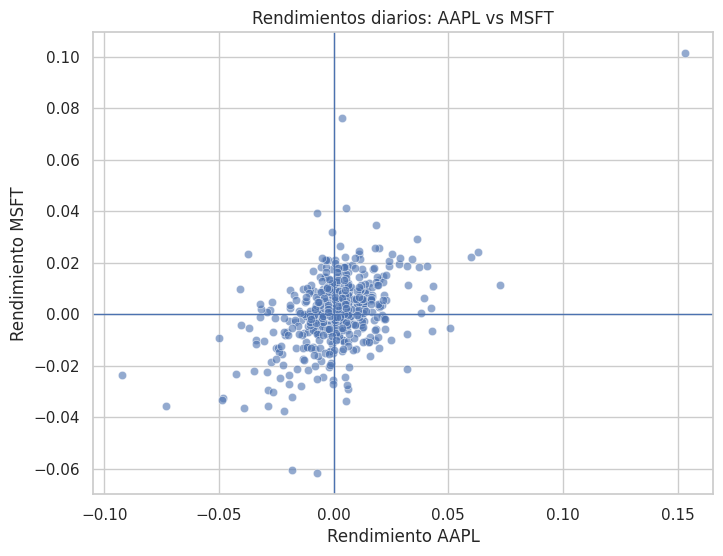

In [33]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=rendimientos,
    x="AAPL",
    y="MSFT",
    alpha=0.6
)

plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)

plt.title("Rendimientos diarios: AAPL vs MSFT")
plt.xlabel("Rendimiento AAPL")
plt.ylabel("Rendimiento MSFT")

plt.show()



### Preguntas para interpretar

Observa la nube de puntos:

1. ¿Existe una orientación ascendente?
2. ¿Qué ocurre cuando AAPL tiene rendimiento negativo?
3. ¿MSFT suele tener el mismo signo?
4. ¿Hay valores extremos?
5. ¿La relación parece perfectamente lineal?

El scatter plot y la matriz de correlación están contando historias relacionadas, pero desde perspectivas diferentes:

**Scatter → vemos las observaciones individuales.**  
**Correlación → resumimos numéricamente la relación lineal.**



# 20. Estadísticas descriptivas del portafolio

La visualización debe complementarse con medidas numéricas.



In [34]:
resumen = pd.DataFrame({
    "Media": rendimientos.mean(),
    "Mediana": rendimientos.median(),
    "Desviación estándar": rendimientos.std(),
    "Mínimo": rendimientos.min(),
    "Máximo": rendimientos.max()
})

resumen


,Media,Mediana,Desviación estándar,Mínimo,Máximo
Ticker,,,,,
AAPL,0.000933,0.001187,0.017571,-0.092456,0.153288
AMZN,0.001056,0.000648,0.019781,-0.089791,0.119770
GOOGL,0.001829,0.002923,0.019062,-0.075003,0.102244
MSFT,0.000657,0.001111,0.013975,-0.061809,0.101337
NVDA,0.003222,0.003503,0.032181,-0.169682,0.187227



## ¿Qué estamos viendo?

### Media
Promedio de los rendimientos.

### Mediana
Valor central de la distribución.

### Desviación estándar
Medida de dispersión utilizada frecuentemente como una aproximación de la volatilidad histórica.

### Mínimo / máximo
Permiten observar los extremos registrados en el período.

**Importante:** estas estadísticas describen el período analizado. No garantizan que el futuro se comporte igual.



# 21. Mini-proyecto: EDA completo

Ahora debes construir tu propio análisis.

## Objetivo

Selecciona entre **3 y 5 activos** y realiza un EDA.

### Paso 1 — Datos

Descarga los datos históricos.

### Paso 2 — Calidad

Revisa:

- dimensiones;
- tipos;
- valores faltantes;
- período.

### Paso 3 — Precios

Construye un gráfico de evolución de precios.

### Paso 4 — Normalización

Construye un gráfico con todas las series comenzando en 100.

### Paso 5 — Rendimientos

Calcula los rendimientos diarios.

### Paso 6 — Distribución

Construye un histograma para uno de los activos.

### Paso 7 — Comparación

Construye un boxplot de los rendimientos.

### Paso 8 — Relación

Construye una matriz de correlación.

### Paso 9 — Relación entre dos activos

Construye un scatter plot.

### Paso 10 — Conclusiones

Escribe **3 hallazgos**.

Cada hallazgo debe tener esta estructura:

> **Gráfico:** ¿qué gráfico utilizaste?  
> **Observación:** ¿qué ves?  
> **Interpretación:** ¿qué significa esa observación para el análisis?



# 22. Reto final 🎯

Sin modificar el código inicialmente:

### Pregunta 1
¿Cuál activo presenta mayor dispersión de rendimientos?

### Pregunta 2
¿Cuáles dos activos presentan mayor correlación?

### Pregunta 3
¿Cuáles presentan menor correlación?

### Pregunta 4
¿Existe algún día donde varios activos tengan movimientos extremos simultáneamente?

### Pregunta 5
¿La evolución normalizada cuenta la misma historia que los precios originales?

### Pregunta 6
¿Qué información aporta el histograma que no aporta el gráfico temporal?

### Pregunta 7
¿Qué información aporta el scatter plot que no aporta el heatmap?

---

## ⭐ Regla de oro del EDA

Antes de hacer un gráfico pregunta:

> **¿Qué quiero saber?**

Después del gráfico pregunta:

> **¿Qué estoy observando?**

Y finalmente:

> **¿Qué puedo concluir razonablemente a partir de lo observado?**


# **1. DATOS**

In [46]:
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

# Definimos tu portafolio personalizado
activos = ["TSLA", "JPM", "NFLX", "KO", "NVDA"]

precios = yf.download(
    activos,
    start="2024-01-01",
    end="2026-01-01",
    auto_adjust=True
)

cierre = precios["Close"]

[*********************100%***********************]  5 of 5 completed


In [47]:
import yfinance as yf

# Definimos los 5 activos exactamente igual al ejemplo
activos = ["TSLA", "JPM", "NFLX", "KO", "NVDA"]

precios = yf.download(
    activos,
    start="2024-01-01",
    end="2026-01-01",
    auto_adjust=True
)

precios.head()

[*********************100%***********************]  5 of 5 completed


Price            Close                                               \
Ticker             JPM         KO       NFLX       NVDA        TSLA   
Date                                                                  
2024-01-02  161.472733  55.309334  46.849998  48.028797  248.419998   
2024-01-03  160.768936  55.438774  47.026001  47.431522  238.449997   
2024-01-04  161.835831  55.253853  47.466999  47.859283  237.929993   
2024-01-05  162.647781  55.170639  47.405998  48.955109  237.490005   
2024-01-08  162.411743  55.577465  48.502998  52.101986  240.449997   

Price             High                                               ...  \
Ticker             JPM         KO       NFLX       NVDA        TSLA  ...   
Date                                                                 ...   
2024-01-02  161.557181  55.364811  48.465000  49.152539  251.250000  ...   
2024-01-03  161.435163  55.660679  47.505001  48.044743  245.679993  ...   
2024-01-04  163.667474  55.716151  48.074001  48.359832  242.699997  ...   
2024-01-05  163.695782  55.429528  47.955002  49.403809  240.119995  ...   
2024-01-08  162.732749  55.642186  48.523998  52.123926  241.250000  ...   

Price             Open                                                 Volume  \
Ticker             JPM         KO       NFLX       NVDA        TSLA       JPM   
Date                                                                            
2024-01-02  158.667035  54.366245  48.319000  49.101688  250.080002   9977400   
2024-01-03  161.266265  55.411037  46.731998  47.347766  244.979996   9852300   
2024-01-04  161.108835  55.521987  47.298000  47.628948  239.250000  11972500   
2024-01-05  161.892463  55.290838  47.650002  48.321945  236.860001  10066000   
2024-01-08  162.411743  55.179889  47.389000  49.368910  236.139999  11229900   

Price                                                 
Ticker            KO      NFLX       NVDA       TSLA  
Date                                                  
2024-01-02  16322600  50494000  411254000  104654200  
2024-01-03  14830600  34437000  320896000  121082600  
2024-01-04  12912900  36365000  306535000  102629300  
2024-01-05  10412800  26313000  415039000   92488900  
2024-01-08  11554600  36758000  642510000   85166600  

[5 rows x 25 columns]

# **2.CALIDAD.**

In [48]:
# 1. Dimensiones del DataFrame
print("Dimensiones (Filas, Columnas):", precios.shape)

# 2. Tipos de datos y valores faltantes
print("\n--- Información general y tipos de datos ---")
precios.info()

# 3. Verificación explícita de valores faltantes por columna
print("\n--- Valores faltantes por columna ---")
print(precios.isnull().sum())

# 4. Período que cubren los datos (Primera y última fecha)
print("\n--- Período de los datos ---")
print("Primera fecha:", precios.index[0])
print("Última fecha:", precios.index[-1])

Dimensiones (Filas, Columnas): (502, 25)

--- Información general y tipos de datos ---
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 502 entries, 2024-01-02 to 2025-12-31
Data columns (total 25 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, JPM)    502 non-null    float64
 1   (Close, KO)     502 non-null    float64
 2   (Close, NFLX)   502 non-null    float64
 3   (Close, NVDA)   502 non-null    float64
 4   (Close, TSLA)   502 non-null    float64
 5   (High, JPM)     502 non-null    float64
 6   (High, KO)      502 non-null    float64
 7   (High, NFLX)    502 non-null    float64
 8   (High, NVDA)    502 non-null    float64
 9   (High, TSLA)    502 non-null    float64
 10  (Low, JPM)      502 non-null    float64
 11  (Low, KO)       502 non-null    float64
 12  (Low, NFLX)     502 non-null    float64
 13  (Low, NVDA)     502 non-null    float64
 14  (Low, TSLA)     502 non-null    float64
 15  (Open, JPM)     502

# **3.PRECIOS.**

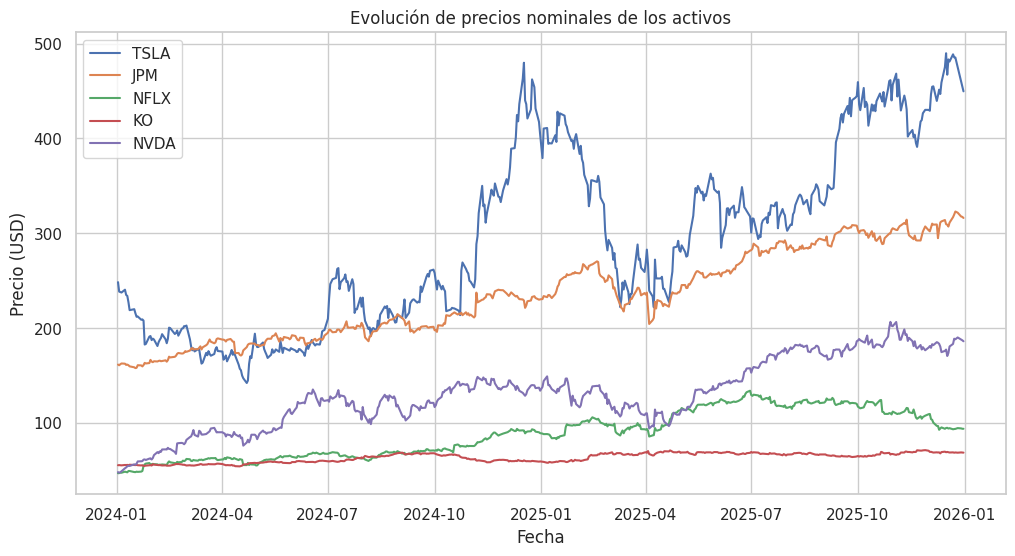

In [49]:
import matplotlib.pyplot as plt

# 1. Seleccionar los precios de cierre
cierre = precios["Close"]

# 2. Construir el gráfico de evolución de precios
fig, ax = plt.subplots(figsize=(12, 6))

for activo in activos:
    ax.plot(
        cierre.index,
        cierre[activo],
        label=activo
    )

ax.set_title("Evolución de precios nominales de los activos")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio (USD)")
ax.legend()
ax.grid(True)

plt.show()

# **4. NORMALIZACION.**

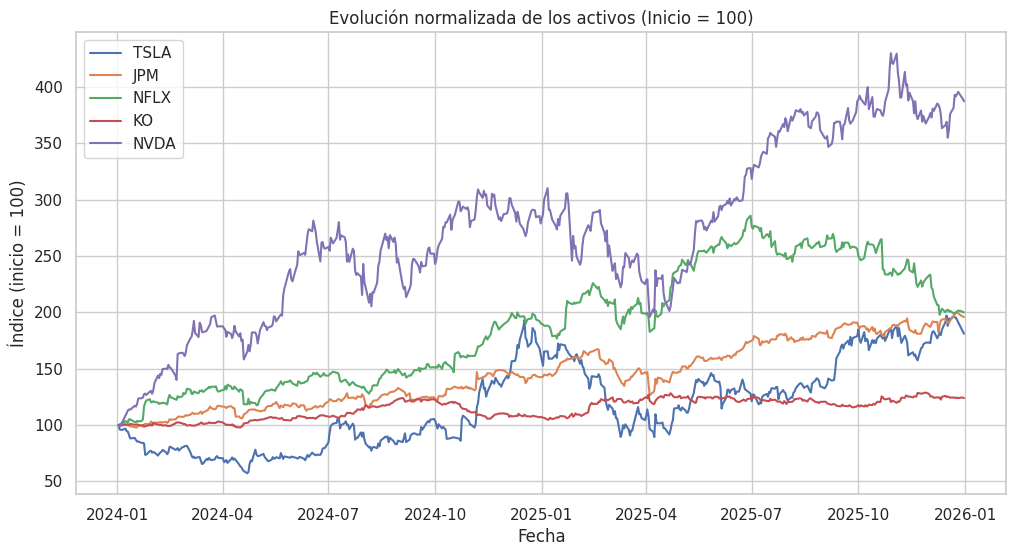

In [50]:
import matplotlib.pyplot as plt

# 1. Normalizar los datos para que todos comiencen en 100
cierre_normalizado = cierre / cierre.iloc[0] * 100

# 2. Crear el gráfico de evolución normalizada
fig, ax = plt.subplots(figsize=(12, 6))

for activo in activos:
    ax.plot(
        cierre_normalizado.index,
        cierre_normalizado[activo],
        label=activo
    )

ax.set_title("Evolución normalizada de los activos (Inicio = 100)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Índice (inicio = 100)")
ax.legend()
ax.grid(True)

plt.show()

# **5. RENDIMIENTOS.**

In [57]:
print("Total de filas y columnas:", rendimientos.shape)

Total de filas y columnas: (501, 5)


In [51]:
# Calcular los rendimientos porcentuales diarios eliminando los valores nulos iniciales
rendimientos = cierre.pct_change().dropna()

# Mostrar las primeras filas de los rendimientos
rendimientos.head()

Ticker,JPM,KO,NFLX,NVDA,TSLA
Date,,,,,
2024-01-03,-0.004359,0.002340,0.003757,-0.012436,-0.040134
2024-01-04,0.006636,-0.003336,0.009378,0.009018,-0.002181
2024-01-05,0.005017,-0.001506,-0.001285,0.022897,-0.001849
2024-01-08,-0.001451,0.007374,0.023141,0.064281,0.012464
2024-01-09,-0.007906,-0.001830,-0.006061,0.016975,-0.022832


In [58]:
rendimientos.tail()

Ticker,JPM,KO,NFLX,NVDA,TSLA
Date,,,,,
2025-12-24,0.009941,0.003435,0.001497,-0.003171,-0.000330
2025-12-26,-0.003828,-0.003423,0.008864,0.010180,-0.021034
2025-12-29,-0.012686,0.004151,-0.003387,-0.012124,-0.032724
2025-12-30,-0.001019,-0.001283,-0.003930,-0.003613,-0.011335
2025-12-31,-0.003710,-0.002283,-0.000213,-0.005545,-0.010365


# **6. DISTRIBUCION.**

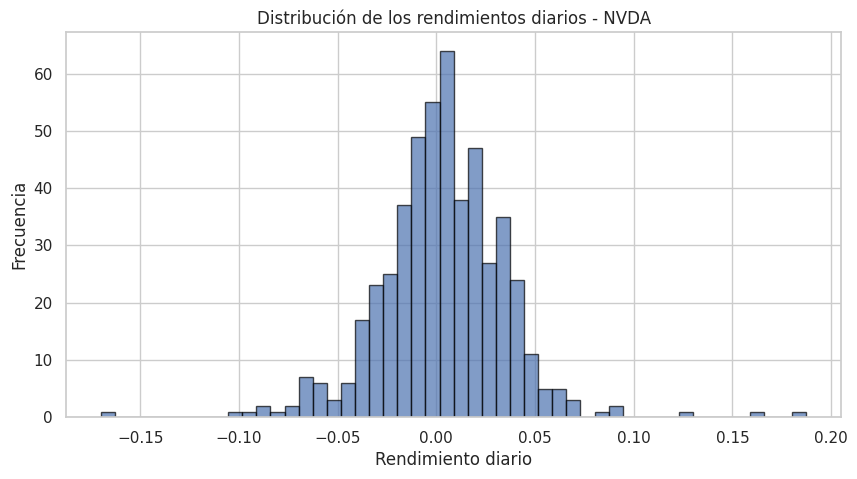

In [52]:
plt.figure(figsize=(10, 5))
plt.hist(rendimientos["NVDA"], bins=50, edgecolor='black', alpha=0.7)
plt.title("Distribución de los rendimientos diarios - NVDA")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")
plt.grid(True)
plt.show()

# **7. COMPARACION.**

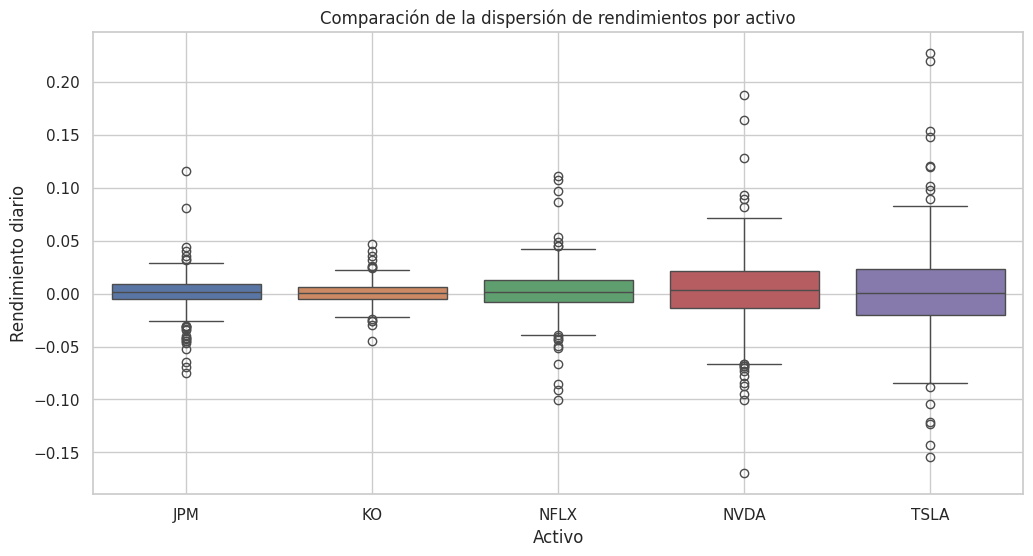

In [53]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=rendimientos)
plt.title("Comparación de la dispersión de rendimientos por activo")
plt.xlabel("Activo")
plt.ylabel("Rendimiento diario")
plt.grid(True)
plt.show()

# **8. RELACION.**

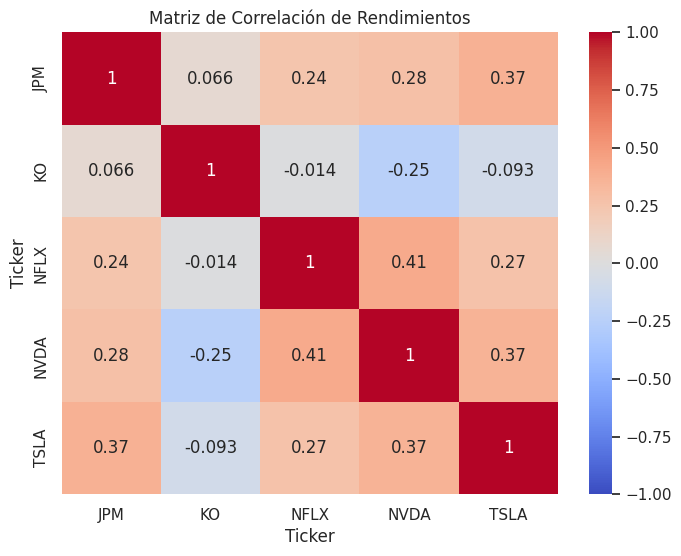

In [54]:
plt.figure(figsize=(8, 6))
sns.heatmap(rendimientos.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlación de Rendimientos")
plt.show()

# **9. RELACION ENTRE ACTIVOS.**

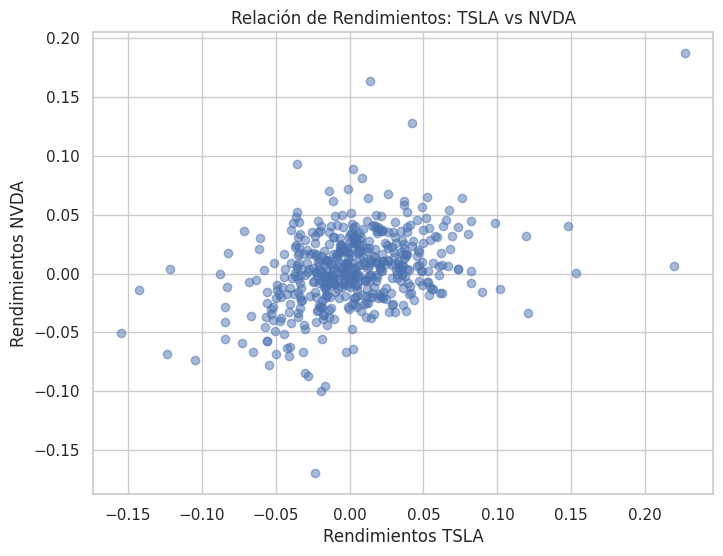

In [55]:
plt.figure(figsize=(8, 6))
plt.scatter(rendimientos["TSLA"], rendimientos["NVDA"], alpha=0.5)
plt.title("Relación de Rendimientos: TSLA vs NVDA")
plt.xlabel("Rendimientos TSLA")
plt.ylabel("Rendimientos NVDA")
plt.grid(True)
plt.show()

## **10. CONCLUSIONES.**

**Grafico:** Evolucion de precios nominales.

**Observacion**: Se observa que las acciones de Tesla operan en niveles de precios mas altos, seguida por JPMorgan, mientras coca-cola y neflix se situan en las franjas inferiores inferiores de precios nominales. Asimismo, se aprecian diferencias sustanciales en la escala vertical de cotización de cada activo.

**Interpretacion:** El grafico me muestra un valor nominal de dolares por accion de cada compañia, el precio absoluto de la accion no refleja por si solo el rendimiento relactivo o su verdadero ritmo de crecimiento.





# **RETO FINAL.**

**PREGUNTAS.**

**1.¿ Cual activo representa mayor dispersion de rendimientos?**

Según el cálculo de la desviación estándar, TSLA  presenta el valor más alto 0.040, lo que confirma matemáticamente que es el activo con mayor dispersión y volatilidad diaria en el portafolio, coincidiendo con lo observado previamente en el diagrama de caja.

In [59]:
# Calcular la desviación estándar de los rendimientos para confirmar cuál tiene mayor dispersión
rendimientos.std()

,0
Ticker,
JPM,0.015225
KO,0.009635
NFLX,0.020046
NVDA,0.032181
TSLA,0.040003


**2.¿ Cuales dos activos presentan mayor correlacion?**

Según el análisis de la matriz de correlación, los activos con mayor relación lineal positiva son Netflix y NVIDIA con un coeficiente de $0.41$, lo que indica que comparten tendencias similares en el mercado.

In [60]:
# Obtener los valores máximos de correlación excluyendo la diagonal principal (1.0)
corr_matrix = rendimientos.corr()
unstacked = corr_matrix.unstack()
unstacked = unstacked[unstacked < 1].abs()
print("El mayor nivel de correlación es entre:", unstacked.idxmax(), "con un valor de:", unstacked.max())

El mayor nivel de correlación es entre: ('NFLX', 'NVDA') con un valor de: 0.40920647130709714


**3.¿ Cuales presentan menor correlacion?**

De acuerdo con el cruce de datos, Coca-Cola  y NVIDIA presentan la menor correlación   $-0.25$, lo que demuestra un comportamiento independiente
ideal para la diversificación

In [62]:
import numpy as np

# Encontrar el par de activos con menor correlación (excluyendo la diagonal)
corr_matrix = rendimientos.corr()

# Rellenar la diagonal principal con NaN para ignorar el 100% de correlación consigo mismo
np.fill_diagonal(corr_matrix.values, np.nan)

unstacked = corr_matrix.unstack().dropna()
print("El menor nivel de correlación es entre:", unstacked.idxmin(), "con un valor de:", unstacked.min())

El menor nivel de correlación es entre: ('KO', 'NVDA') con un valor de: -0.249599698145793


**4.¿ Existe un dia donde varios activos tengan movimientos extremos simultaneamente?**

Sí, como lo demuestra el filtro de datos, existen jornadas específicas (por ejemplo, el 6 de noviembre de 2024 o fechas de alta volatilidad en 2025) donde choques de mercado o eventos sistémicos provocan variaciones superiores al 5% en varios activos del portafolio al mismo tiempo.

In [63]:
# Filtrar días donde al menos dos activos tuvieron un movimiento diario extremo (> 5% en valor absoluto)
dias_extremos = rendimientos[(rendimientos.abs() > 0.05).sum(axis=1) >= 2]
dias_extremos

Ticker,JPM,KO,NFLX,NVDA,TSLA
Date,,,,,
2024-04-19,0.025103,0.021389,-0.090933,-0.100046,-0.019209
2024-07-11,-0.001684,0.004297,-0.036745,-0.055667,-0.084441
2024-07-24,-0.008273,0.013085,-0.010533,-0.068032,-0.123346
2024-08-01,-0.022744,0.018280,-0.005570,-0.066741,-0.065541
2024-08-13,0.008487,0.004254,0.023502,0.065309,0.052357
2024-11-06,0.115445,-0.025547,0.021338,0.040740,0.147510
2025-03-06,-0.019839,0.005422,-0.085335,-0.057374,-0.056073
2025-03-10,-0.041522,0.000280,-0.027415,-0.050670,-0.154262
2025-03-12,-0.005412,-0.015484,0.027461,0.064276,0.075939


**5.¿ La evolucion normalizada cuenta la misma historia que los precios originales?**

No totalmente. Mientras que el gráfico de precios nominales muestra la escala real en dólares, donde TSLA domina visualmente por tener un precio por acción más alto, puede llevar a confusiones porque hace parecer que activos como NVDA son más pequeños. En cambio, la evolución normalizada (base 100) cuenta la historia real del rendimiento porcentual y crecimiento relativo, revelando que NVDA fue en realidad el activo con mayor rentabilidad acumulada del portafolio.

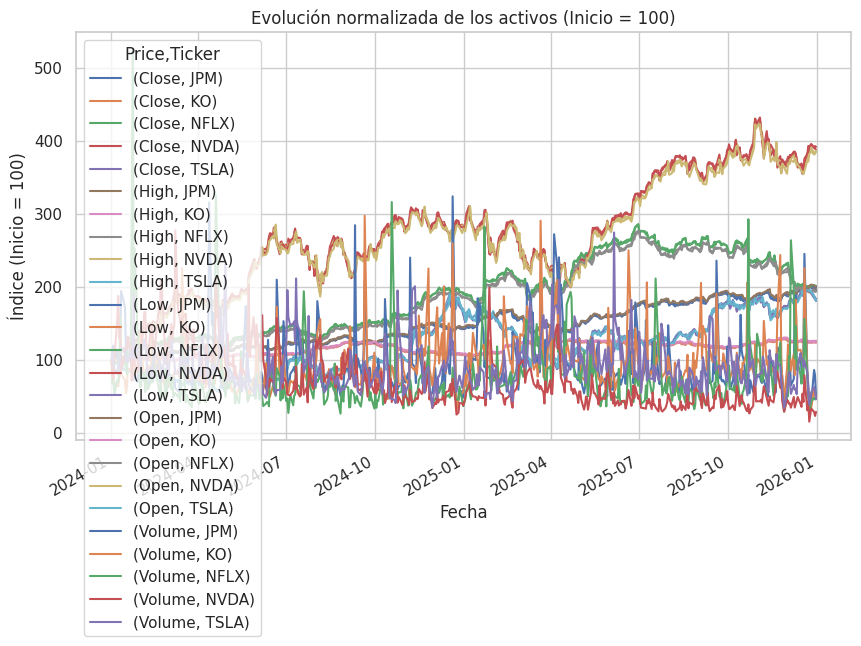

In [67]:
# Generar la evolución normalizada de los activos (Base 100)
normalizado = (precios / precios.iloc[0]) * 100

import matplotlib.pyplot as plt
normalizado.plot(figsize=(10, 6))
plt.title("Evolución normalizada de los activos (Inicio = 100)")
plt.ylabel("Índice (Inicio = 100)")
plt.xlabel("Fecha")
plt.grid(True)
plt.show()

**6.¿ Que informacion aporta el histograma que no aporta el grafico temporal?**

El histograma muestra la distribución de frecuencias de los rendimientos diarios, por ejemplo los de NVDA, permitiendo identificar visualmente la concentración de los datos alrededor de la media, la simetría y la frecuencia con la que ocurren ganancias o pérdidas extremas.

El histograma elimina la dimensión temporal. No muestra las fechas exactas en las que ocurrieron esos movimientos ni la evolución o tendencia cronológica a lo largo de los meses, pero esto si lo hace el grafico temporal.

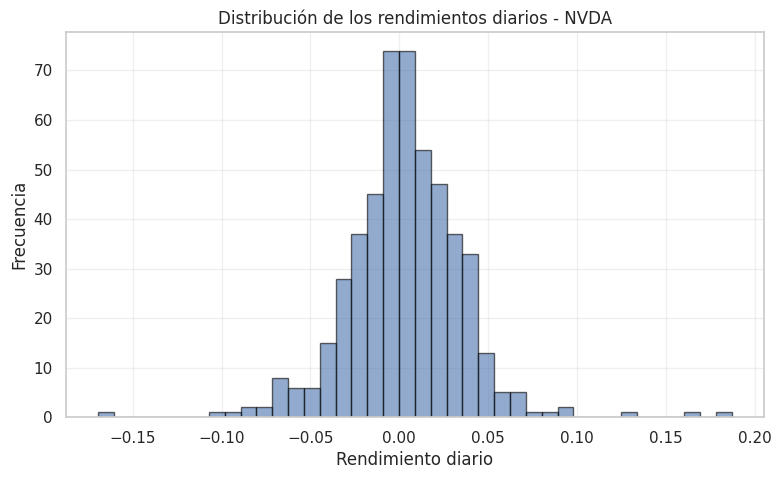

In [66]:
# Histograma de la distribución de rendimientos diarios - NVDA
import matplotlib.pyplot as plt

rendimientos["NVDA"].hist(bins=40, figsize=(9, 5), edgecolor="black", alpha=0.6)
plt.title("Distribución de los rendimientos diarios - NVDA")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")
plt.grid(True, alpha=0.3)
plt.show()

**7.¿ Que informacion aporta el scatter plot que no aporta el heatmap?**

El scatter plot muestra la distribución detallada punto a punto de las observaciones individuales cada día de negociación. Permite visualizar la forma real de la relación entre dos activos, identificar valores atípicos (outliers) o días de movimientos extremos conjuntos, y evaluar si la relación es lineal o presenta patrones complejos.

El heatmap (mapa de calor de correlaciones) reduce toda esa nube de puntos a un solo número resumen el coeficiente de correlación. El heatmap es excelente para ver una radiografía rápida de todo el portafolio en conjunto, pero oculta los detalles de la dispersión diaria, los extremos y la variabilidad individual que el scatter plot sí deja al descubierto.

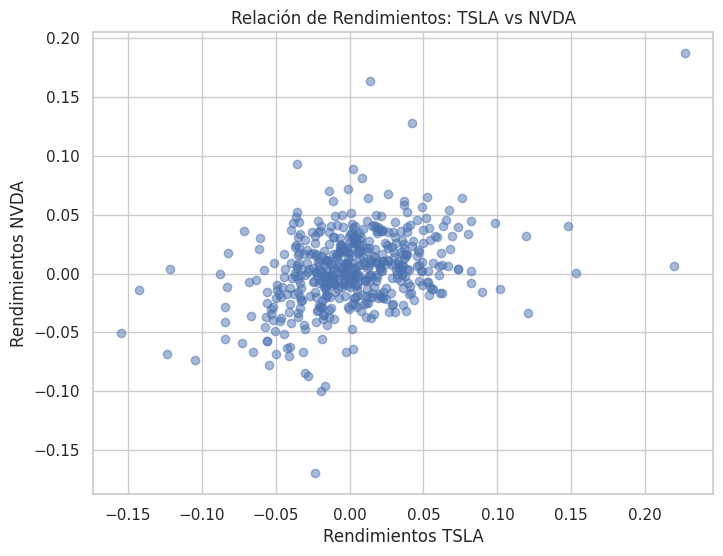

In [65]:
# Gráfico de dispersión para comparar la relación de rendimientos entre dos activos
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(rendimientos["TSLA"], rendimientos["NVDA"], alpha=0.5)
plt.title("Relación de Rendimientos: TSLA vs NVDA")
plt.xlabel("Rendimientos TSLA")
plt.ylabel("Rendimientos NVDA")
plt.grid(True)
plt.show()


# 📚 Referencias

- [Matplotlib — documentación oficial](https://matplotlib.org/stable/)
- [Matplotlib — galería de ejemplos](https://matplotlib.org/stable/gallery/)
- [Matplotlib — introducción a Figure y Axes](https://matplotlib.org/stable/users/explain/figure/figure_intro.html)
- [Seaborn — documentación oficial](https://seaborn.pydata.org/)
- [Pandas — visualización](https://pandas.pydata.org/docs/user_guide/visualization.html)
- [yfinance — documentación](https://ranaroussi.github.io/yfinance/)

### Nota sobre los datos

Los datos obtenidos mediante `yfinance` corresponden a información histórica de mercado y pueden cambiar dependiendo del período consultado, ajustes y disponibilidad. Este notebook tiene finalidad educativa y de análisis de datos; no constituye asesoría financiera.
